<a href="https://colab.research.google.com/github/NisalJayaweera/EN3160-Fitting-and-Alignment/blob/main/notebooks/Q3_Homography_Transparency_Resolutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 Assignment 02 — Question 3: Homography and Image Compositing

This notebook presents **two image-pair experiments**, as required by Question 3:

1. **University of Moratuwa crest → university building façade** (transparent PNG; alpha blending).
2. **Sri Lankan flag → Sigiriya rock face** (opaque WebP; quadrilateral mask and feathered compositing).

For both pairs, we choose four source and destination points, compute a planar projective homography, warp the source into the target image, and discuss the quality and limitations of the alignment. All four input images are downloaded from the repository's `main/images/` folder when they are not cached locally.

## 1. Input images and reproducibility

All four input files are stored in [the GitHub `images/` folder](https://github.com/NisalJayaweera/EN3160-Fitting-and-Alignment/tree/main/images). The loader downloads each file from the raw GitHub URL if no readable local copy is available. Thus, the notebook works in a fresh Google Colab runtime without manual uploads.

**Coordinates:** Image points use `(x, y)` in pixels, with the origin at the top-left. Each four-point list is ordered **top-left, top-right, bottom-right, bottom-left**.

Background (H, W, C): (813, 1535, 3)
Logo (H, W, C): (325, 306, 4)


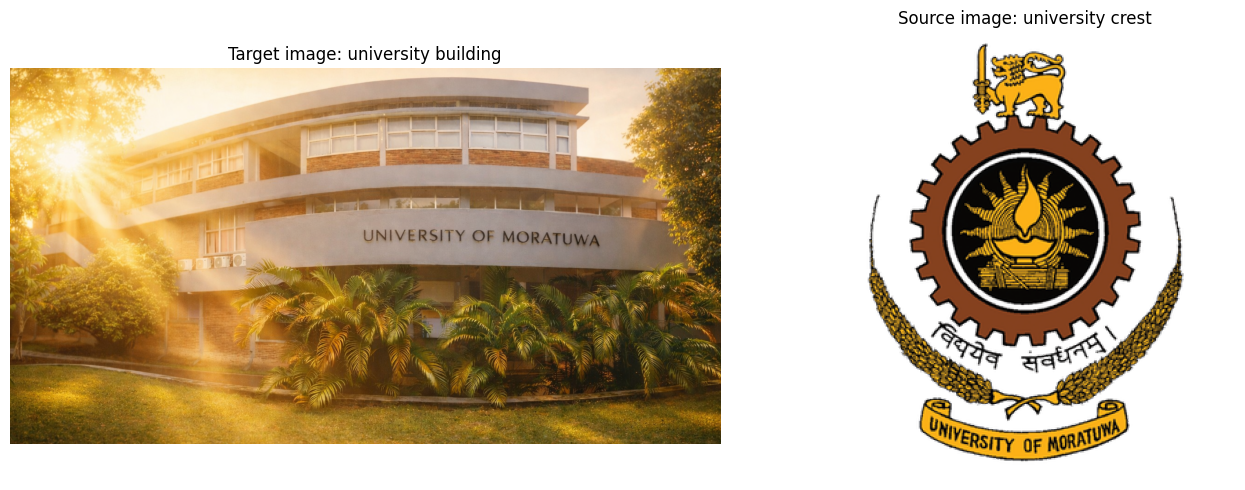

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
IMAGE_DIR = ROOT / "images"
OUTPUT_DIR = ROOT / "results"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

GITHUB_RAW = ("https://raw.githubusercontent.com/"
              "NisalJayaweera/EN3160-Fitting-and-Alignment/main/images/")
BACKGROUND_PATH = IMAGE_DIR / "bgmain-mldlys04.png"
LOGO_PATH = IMAGE_DIR / "University_of_Moratuwa_logo.png"

def ensure_github_image(path: Path, flags: int):
    """Read a cached image or download and decode it from GitHub."""
    img = cv2.imread(str(path), flags) if path.is_file() else None
    if img is not None:
        print(f"Using cached image: {path}")
        return img
    url = GITHUB_RAW + path.name
    print(f"Downloading from GitHub: {url}")
    try:
        req = Request(url, headers={"User-Agent": "EN3160-assignment-notebook"})
        with urlopen(req, timeout=45) as response:
            data = response.read()
    except Exception as exc:
        raise RuntimeError(f"Unable to download {path.name} from {url}: {exc}") from exc
    decoded = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), flags)
    if decoded is None:
        raise ValueError(f"Downloaded data is not a valid image: {url}")
    path.write_bytes(data)
    return decoded

background = ensure_github_image(BACKGROUND_PATH, cv2.IMREAD_COLOR)
logo = ensure_github_image(LOGO_PATH, cv2.IMREAD_UNCHANGED)
if logo.ndim != 3 or logo.shape[2] != 4:
    raise ValueError("The source logo must be an RGBA PNG with transparency.")
print("Background (H, W, C):", background.shape)
print("Logo (H, W, C):", logo.shape)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
axs[0].imshow(cv2.cvtColor(background, cv2.COLOR_BGR2RGB))
axs[0].set_title("Target image: university building")
axs[1].imshow(cv2.cvtColor(logo, cv2.COLOR_BGRA2RGBA))
axs[1].set_title("Source image: university crest")
for ax in axs: ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Four-point correspondence

The source points are the four corners of the logo raster. The destination points are manually selected points on the approximately planar front fascia, in the same order: top-left, top-right, bottom-right, bottom-left. These pixel coordinates refer specifically to the supplied **1535 × 813** photograph. If the image changes resolution, reselect the points.

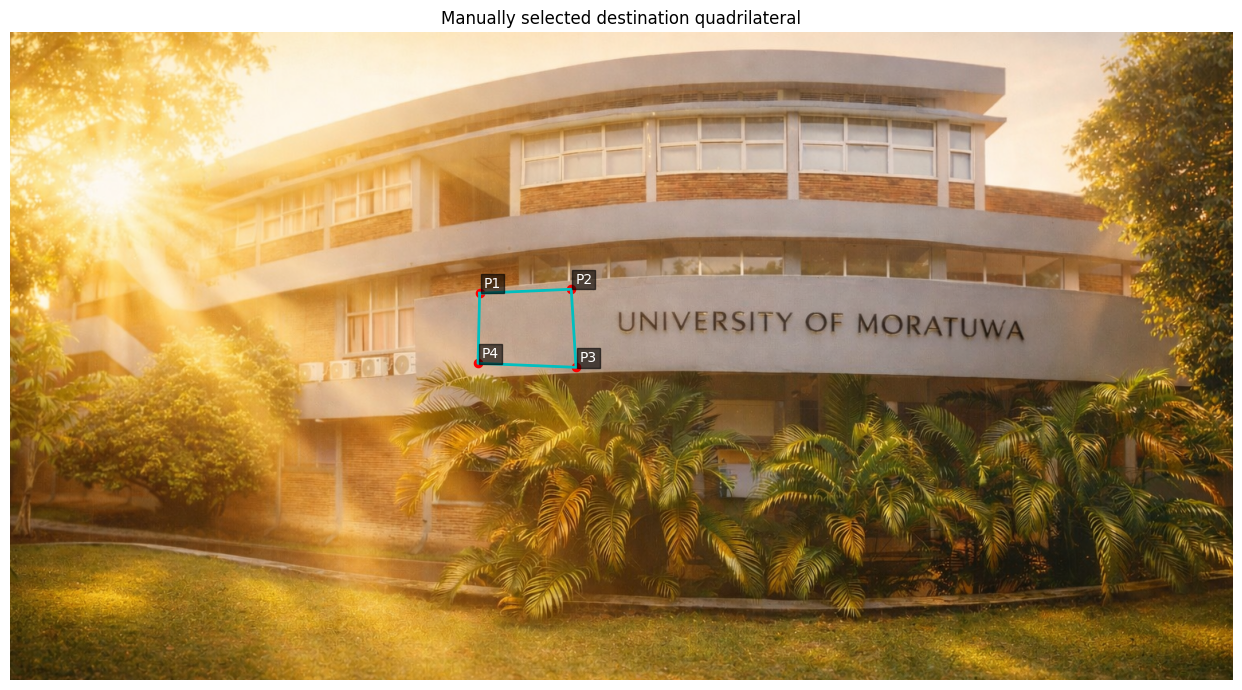

Source corners:
 [[  0.   0.]
 [305.   0.]
 [305. 324.]
 [  0. 324.]]
Destination corners:
 [[589. 327.]
 [704. 322.]
 [710. 420.]
 [587. 415.]]


In [2]:
h, w = logo.shape[:2]
src_pts = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
dst_pts = np.float32([[589, 327], [704, 322], [710, 420], [587, 415]])

preview = cv2.cvtColor(background.copy(), cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(figsize=(15, 7))
ax.imshow(preview)
polygon = np.vstack([dst_pts, dst_pts[0]])
ax.plot(polygon[:, 0], polygon[:, 1], 'c-', linewidth=2)
for i, (x, y) in enumerate(dst_pts):
    ax.scatter(x, y, c='red', s=35)
    ax.text(x + 5, y - 7, f'P{i+1}', color='white', fontsize=10, bbox={'facecolor':'black','alpha':0.6,'pad':2})
ax.set_title('Manually selected destination quadrilateral')
ax.axis('off'); plt.tight_layout(); plt.show()
print('Source corners:\n', src_pts)
print('Destination corners:\n', dst_pts)

## 3. Homography estimation

A homography maps a point $(x,y)$ on the source plane to $(x',y')$ on the target plane:

$$\lambda\begin{bmatrix}x'\\y'\\1\end{bmatrix}=H\begin{bmatrix}x\\y\\1\end{bmatrix},\qquad H\in\mathbb{R}^{3\times3}.$$

There are eight independent degrees of freedom because the matrix is defined up to scale. Four non-collinear point correspondences determine a homography. `cv2.getPerspectiveTransform` estimates it directly; RANSAC is unnecessary when there are exactly four manually selected correspondences. The reprojection check below tests whether the four source corners map to the intended target corners.

In [3]:
H = cv2.getPerspectiveTransform(src_pts, dst_pts)
projected = cv2.perspectiveTransform(src_pts.reshape(-1, 1, 2), H).reshape(-1, 2)
corner_error = np.linalg.norm(projected - dst_pts, axis=1)
print('Homography H:\n', H)
print('Corner reprojection errors (pixels):', np.round(corner_error, 6))
assert np.all(np.isfinite(H)) and np.max(corner_error) < 1e-2


Homography H:
 [[ 1.48609884e-01 -1.15262274e-01  5.89000000e+02]
 [-1.20878462e-01  1.94480381e-01  3.27000000e+02]
 [-3.24487637e-04 -1.85842307e-04  1.00000000e+00]]
Corner reprojection errors (pixels): [0. 0. 0. 0.]


## 4. Perspective warping and alpha compositing — pair 1

The transparent logo is warped with `cv2.warpPerspective`. Its alpha channel is used to blend it into the photograph:

$$I_{\mathrm{out}}(x,y)=\alpha(x,y)I_{\mathrm{warp}}(x,y)+[1-\alpha(x,y)]I_{\mathrm{background}}(x,y).$$

We apply an additional opacity factor of 0.45. A warped alpha value of zero leaves the background unchanged.

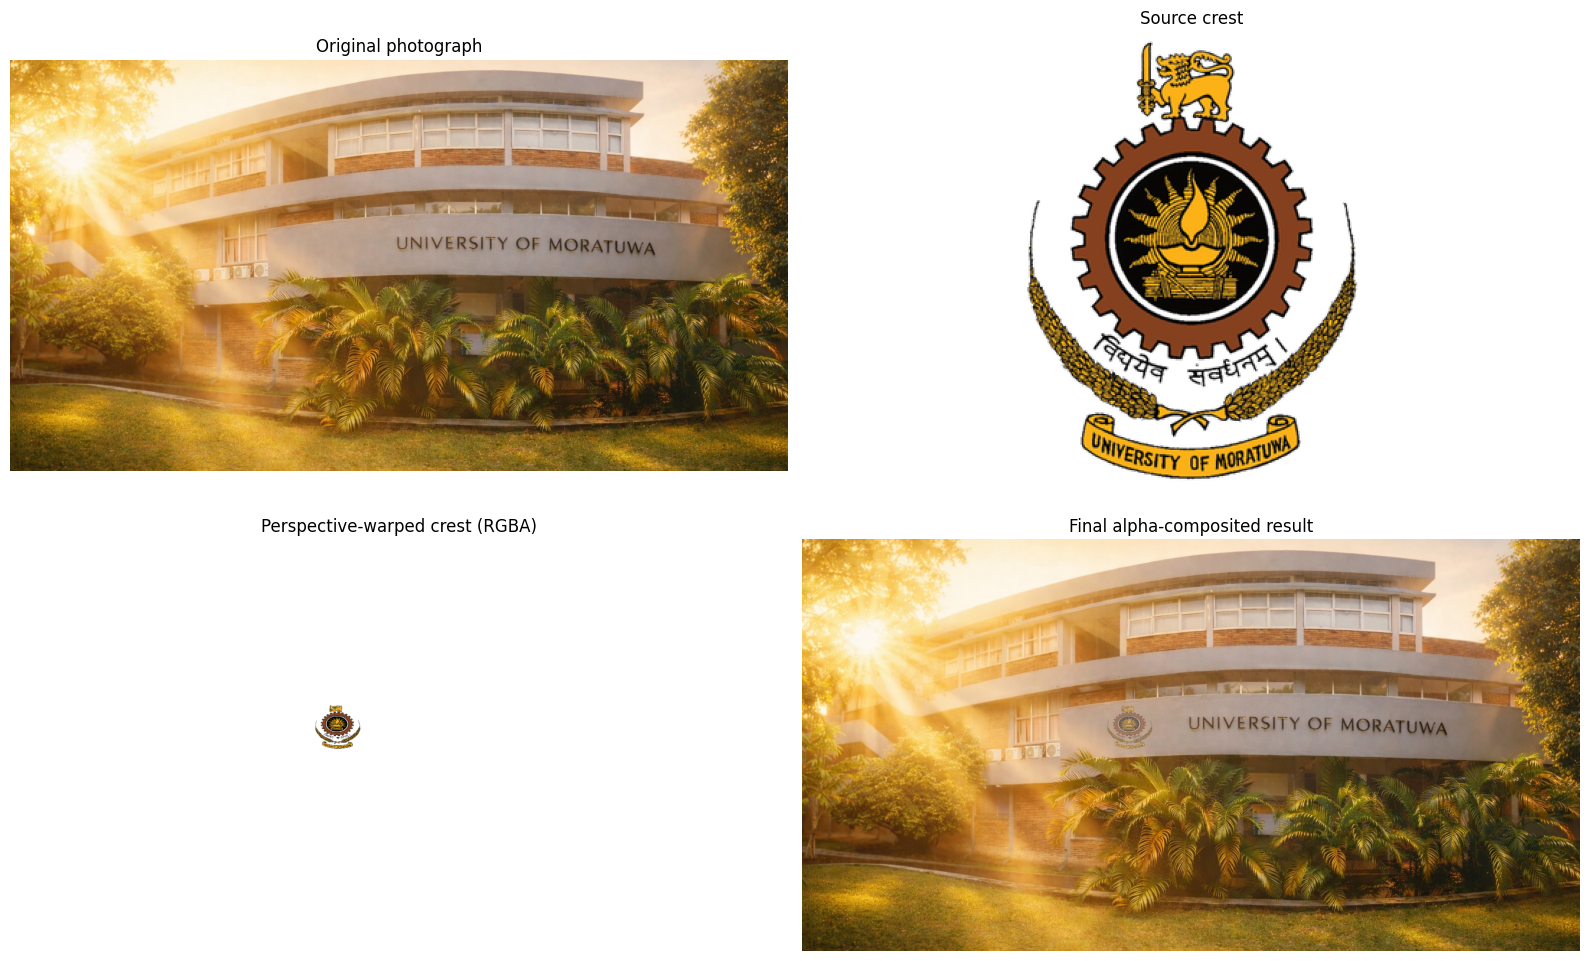

In [4]:
bh, bw = background.shape[:2]
warped = cv2.warpPerspective(logo, H, (bw, bh), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0, 0))
opacity = 0.45
alpha = (warped[:, :, 3:4].astype(np.float32) / 255.0) * opacity
composite = (alpha * warped[:, :, :3].astype(np.float32)
             + (1 - alpha) * background.astype(np.float32))
composite = np.clip(composite, 0, 255).astype(np.uint8)
cv2.imwrite(str(OUTPUT_DIR / 'q3_pair1_composite.png'), composite)
cv2.imwrite(str(OUTPUT_DIR / 'q3_pair1_warped_logo.png'), warped)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0, 0].imshow(cv2.cvtColor(background, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title('Original photograph')
axes[0, 1].imshow(cv2.cvtColor(logo, cv2.COLOR_BGRA2RGBA)); axes[0, 1].set_title('Source crest')
axes[1, 0].imshow(cv2.cvtColor(warped, cv2.COLOR_BGRA2RGBA)); axes[1, 0].set_title('Perspective-warped crest (RGBA)')
axes[1, 1].imshow(cv2.cvtColor(composite, cv2.COLOR_BGR2RGB)); axes[1, 1].set_title('Final alpha-composited result')
for ax in axes.flat: ax.axis('off')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'q3_pair1_comparison.png', dpi=160); plt.show()

## 5. Pair 1 discussion — university crest on the façade

The building's pale front fascia provides a relatively smooth, visually suitable placement area, and the chosen polygon avoids the prominent existing lettering. The crest's transparent background prevents a rectangular patch from covering the building. The four correspondences are fitted essentially exactly; the reported **corner reprojection error only checks the four chosen correspondences**, not the realism of the composite.

The main limitation is that the fascia is slightly **curved**. A homography describes a plane, so it only approximates the surface locally. The overlay also does not model wall texture, shadows, or environmental lighting. A piecewise warp or surface-aware projection could improve realism.

## 6. Image pair 2 — Sri Lankan flag on the Sigiriya rock face

**Source:** `Flag_of_Sri_Lanka.svg.webp` (opaque flag illustration).  
**Target:** `Sigiriya+Rock.webp` (photograph of Sigiriya).

The rock face is a meaningful outdoor surface for a virtual flag projection. We choose a broad, approximately flat **local patch** of the visible rock face rather than projecting across the entire irregular rock. The selected destination quadrilateral gives a perspective effect. Unlike the transparent university crest, the flag is opaque, so a warped polygon mask and mild feathering are used to blend its boundary.

**Important limitation:** Sigiriya's rock surface is three-dimensional and uneven, not a perfect plane. The homography is therefore an approximation for this demonstration, not a physically exact texture map.

Flag: (1920, 3840, 3) | Sigiriya: (3125, 2500, 3)


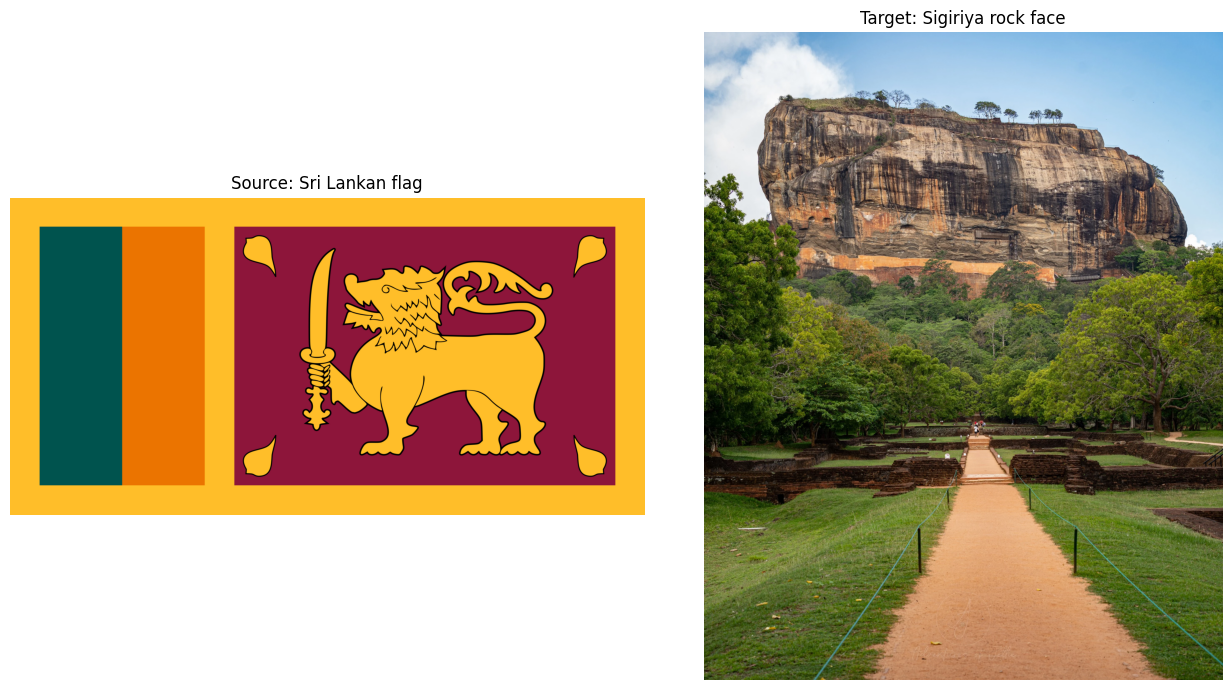

In [5]:
FLAG_PATH = IMAGE_DIR / "Flag_of_Sri_Lanka.svg.webp"
SIGIRIYA_PATH = IMAGE_DIR / "Sigiriya+Rock.webp"
flag = ensure_github_image(FLAG_PATH, cv2.IMREAD_COLOR)
sigiriya = ensure_github_image(SIGIRIYA_PATH, cv2.IMREAD_COLOR)
print("Flag:", flag.shape, "| Sigiriya:", sigiriya.shape)

fig, ax = plt.subplots(1, 2, figsize=(13, 7))
ax[0].imshow(cv2.cvtColor(flag, cv2.COLOR_BGR2RGB))
ax[0].set_title("Source: Sri Lankan flag")
ax[1].imshow(cv2.cvtColor(sigiriya, cv2.COLOR_BGR2RGB))
ax[1].set_title("Target: Sigiriya rock face")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()

### 6.1 Four-point correspondences

The source quadrilateral consists of the flag's image corners. Destination points were selected manually within the rock's broad central face. The order of points must be consistent between the two sets. These manually selected coordinates are **design choices for the virtual projection**, not measured physical landmarks.

The destination polygon is specified relative to a reference image size and scaled to the actual loaded photograph. This removes the fixed-resolution assumption. **If the image is cropped or otherwise reframed**, inspect the displayed polygon and adjust the destination points manually.

Sigiriya image size: 2500 x 3125
Destination point scaling: x=1.5263, y=1.5259


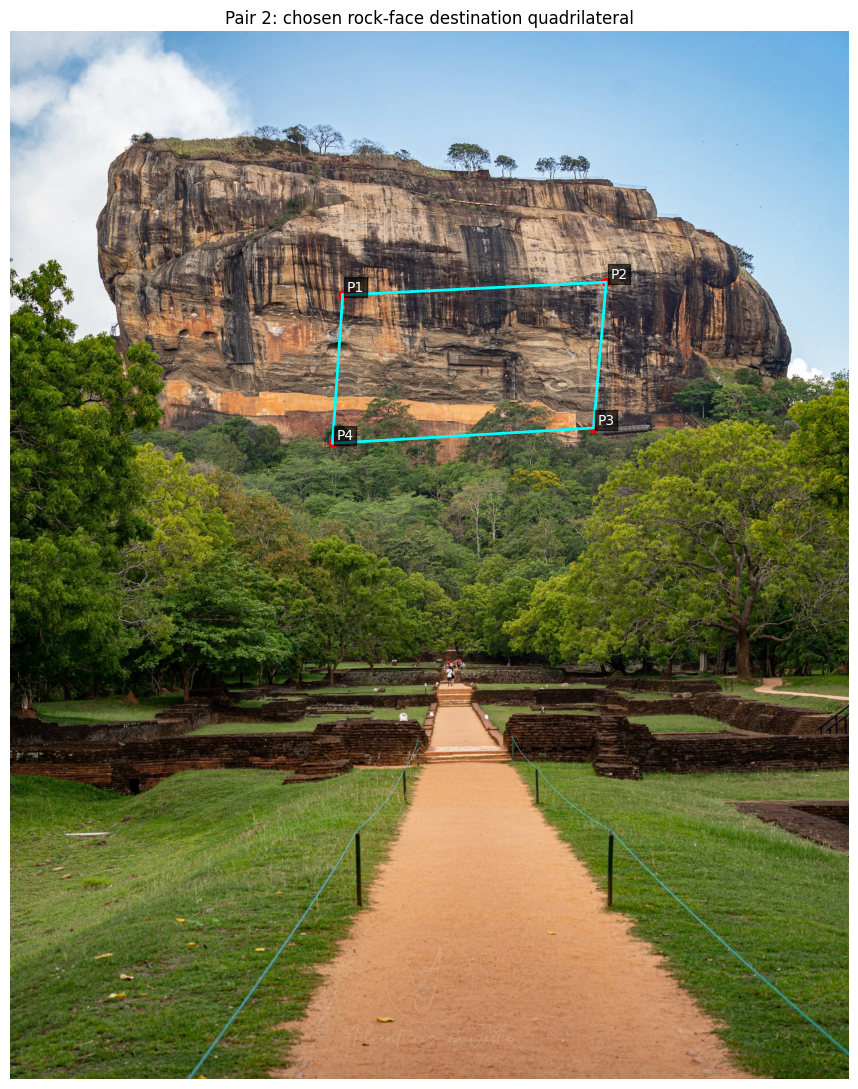

Source corners:
 [[   0.    0.]
 [3839.    0.]
 [3839. 1919.]
 [   0. 1919.]]
Destination corners:
 [[ 992.06354  785.82764]
 [1778.083    747.68066]
 [1739.9268  1182.5562 ]
 [ 961.53845 1228.3325 ]]


In [6]:
fh, fw = flag.shape[:2]
flag_src = np.float32([[0, 0], [fw - 1, 0], [fw - 1, fh - 1], [0, fh - 1]])
# Destination quadrilateral defined in the reference photo (width=1638, height=2048).
# Scale coordinates to the ACTUAL downloaded image dimensions.
# This supports resolution changes when the photo content and crop are unchanged.
reference_width, reference_height = 1638, 2048
reference_dst = np.float32([[650, 515], [1165, 490], [1140, 775], [630, 805]])
actual_height, actual_width = sigiriya.shape[:2]
scale_xy = np.float32([actual_width / reference_width,
                       actual_height / reference_height])
flag_dst = reference_dst * scale_xy
print(f"Sigiriya image size: {actual_width} x {actual_height}")
print(f"Destination point scaling: x={scale_xy[0]:.4f}, y={scale_xy[1]:.4f}")

fig, ax = plt.subplots(figsize=(10, 11))
ax.imshow(cv2.cvtColor(sigiriya, cv2.COLOR_BGR2RGB))
outline = np.vstack([flag_dst, flag_dst[0]])
ax.plot(outline[:, 0], outline[:, 1], color="cyan", lw=2)
for i, (x, y) in enumerate(flag_dst):
    ax.scatter(x, y, color="red", s=35)
    ax.text(x+12, y-12, f"P{i+1}", color="white",
            bbox={"facecolor":"black", "alpha":0.65, "pad":2})
ax.set_title("Pair 2: chosen rock-face destination quadrilateral")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q3_pair2_correspondences.png", dpi=130, bbox_inches="tight")
plt.show()
print("Source corners:\n", flag_src)
print("Destination corners:\n", flag_dst)

### 6.2 Homography estimation and geometric validation

For a source point \(\mathbf{x}=(x,y,1)^T\) and a target point \(\mathbf{x}'\), the projective mapping satisfies \(\lambda\mathbf{x}'=H\mathbf{x}\). Four non-collinear correspondences determine the eight independent degrees of freedom of \(H\) (up to scale). `cv2.getPerspectiveTransform` computes this mapping. A near-zero corner error confirms numerical agreement at the four specified points, **not** accurate mapping of an uneven surface.

In [7]:
H_flag = cv2.getPerspectiveTransform(flag_src, flag_dst)
mapped_corners = cv2.perspectiveTransform(flag_src.reshape(-1, 1, 2), H_flag).reshape(-1, 2)
errors = np.linalg.norm(mapped_corners - flag_dst, axis=1)
print("Pair 2 homography H:\n", H_flag)
print("Corner reprojection errors (px):", np.round(errors, 6))
assert np.all(np.isfinite(H_flag)) and np.max(errors) < 0.01

Pair 2 homography H:
 [[ 2.13394156e-01 -1.05358300e-02  9.92063538e+02]
 [-6.30011499e-03  2.37452581e-01  7.85827637e+02]
 [ 4.86381474e-06  5.58577440e-06  1.00000000e+00]]
Corner reprojection errors (px): [0. 0. 0. 0.]


### 6.3 Warping and masked blending

The flag is warped into the photograph's coordinate system. We also warp a white source mask, which determines the valid projected quadrilateral. A small Gaussian blur softens the mask boundary; an opacity factor of 0.45 allows some underlying rock texture to remain visible. The final image is a **visual composite**, not a physically based projection.

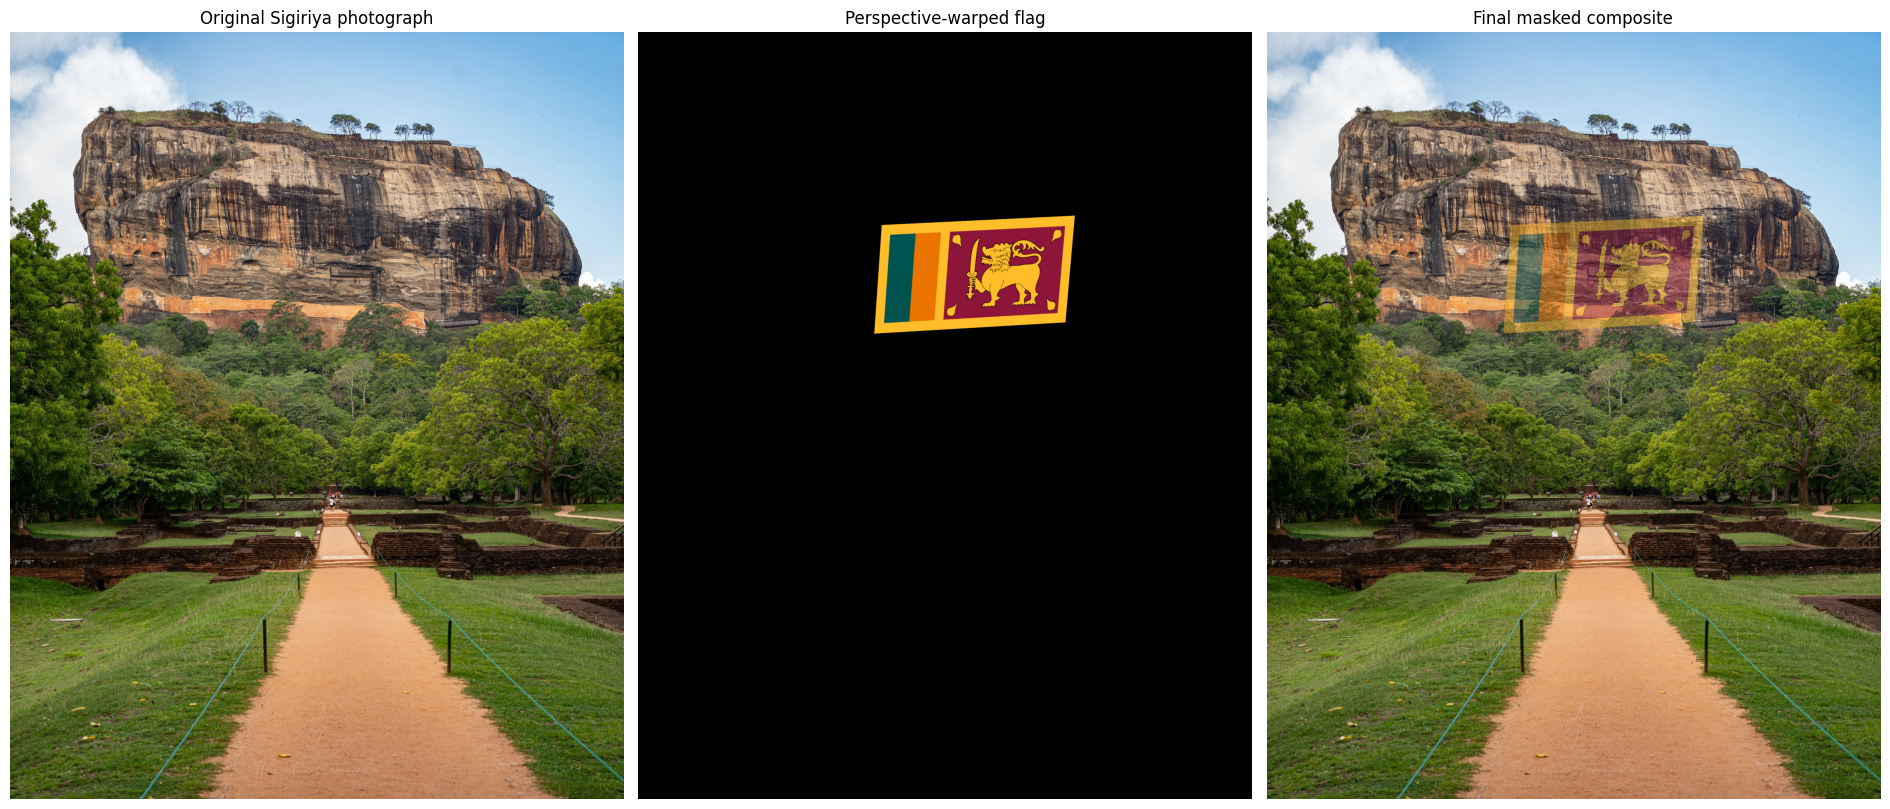

In [8]:
sh, sw = sigiriya.shape[:2]
flag_warped = cv2.warpPerspective(flag, H_flag, (sw, sh),
                                  flags=cv2.INTER_LINEAR,
                                  borderMode=cv2.BORDER_CONSTANT,
                                  borderValue=(0, 0, 0))
source_mask = np.full((fh, fw), 255, dtype=np.uint8)
warped_mask = cv2.warpPerspective(source_mask, H_flag, (sw, sh),
                                   flags=cv2.INTER_LINEAR,
                                   borderMode=cv2.BORDER_CONSTANT,
                                   borderValue=0)
soft_mask = cv2.GaussianBlur(warped_mask, (7, 7), 1.4)
blend_alpha = 0.45 * (soft_mask.astype(np.float32) / 255.0)[..., None]
flag_composite = np.clip(blend_alpha * flag_warped.astype(np.float32)
                         + (1.0 - blend_alpha) * sigiriya.astype(np.float32),
                         0, 255).astype(np.uint8)

cv2.imwrite(str(OUTPUT_DIR / "q3_pair2_composite.png"), flag_composite)
cv2.imwrite(str(OUTPUT_DIR / "q3_pair2_warped_flag.png"), flag_warped)
cv2.imwrite(str(OUTPUT_DIR / "q3_pair2_projection_mask.png"), warped_mask)

fig, ax = plt.subplots(1, 3, figsize=(19, 9))
for a, image, title in zip(ax,
    [sigiriya, flag_warped, flag_composite],
    ["Original Sigiriya photograph", "Perspective-warped flag", "Final masked composite"]):
    a.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q3_pair2_comparison.png", dpi=140, bbox_inches="tight")
plt.show()

## 7. Discussion and comparison of the two image pairs

| Aspect | Pair 1: University crest | Pair 2: Flag at Sigiriya |
|---|---|---|
| Source transparency | Transparent RGBA PNG | Opaque RGB WebP |
| Target region | Pale façade / fascia | Central rock face |
| Geometric model | Four-point planar homography | Four-point planar homography |
| Blending | Warped source alpha | Warped polygon mask with feathering |
| Primary limitation | Curved fascia, lighting | Uneven rock depth, lighting and texture |

Both experiments demonstrate how a homography maps a rectangular graphic to a chosen quadrilateral in another image. The correspondences were selected manually because the task is to **place** a new graphic on a surface, rather than find pre-existing matching features between the two unrelated images.

The first experiment benefits from a transparent source and a relatively small target patch. The second uses an opaque source, so masking is essential to prevent the rest of the source rectangle from obscuring the scene. Both use alpha compositing to preserve some context.

**Geometric accuracy:** The nearly zero corner reprojection error follows from fitting exactly four points. It does not measure physical accuracy on a non-planar façade or rock face. Straight lines in the graphic remain straight after a homography, but they will not conform to a curved or irregular surface.

**Photometric realism:** Neither experiment estimates surface reflectance, occlusion, cast shadows, or spatially varying illumination. The resulting overlays demonstrate projective alignment and compositing, not photorealistic augmented reality.

**Conclusion:** The two image pairs meet the requested four-point correspondence, homography estimation, image warping, and visual-compositing workflow. A surface-aware mesh warp and illumination-aware blending would be appropriate improvements for more realistic results.